# Proyecto Final – Finanzas Computacionales (CO-2067-3)
## Opción 2: Optimización de carteras con predicción de retornos (Random Forest / KNN + Markowitz)

**Flujo:** datos (yfinance) → features → modelos de regresión (RF, KNN, base) → métricas (RMSE, MSE, MAE, matriz de confusión) → test Diebold-Mariano → Frontera Eficiente de Markowitz → Sharpe / Sortino vs cartera igualitaria.

In [1]:
!pip -q install yfinance

## 1. Configuración e imports

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yfinance as yf
from scipy import stats
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             confusion_matrix, f1_score, accuracy_score)

TICKERS    = ["AAPL", "MSFT", "AMZN", "GOOGL", "JPM", "XOM"]
START, END = "2018-01-01", "2026-11-19"
TEST_START = "2025-01-01"     # todo lo anterior = entrenamiento; desde aqui = prueba (out-of-sample)
RF_ANUAL   = 0.04             # tasa libre de riesgo anual (aprox.)
SEED       = 42
np.random.seed(SEED)

## 2. Datos
Descargamos precios ajustados con `yfinance` y calculamos **retornos diarios simples**: r_t = P_t / P_(t-1) - 1.

In [3]:
px = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)["Close"]
px = px[TICKERS].dropna()
rets = px.pct_change().dropna()
print(px.shape, px.index.min().date(), "->", px.index.max().date())
rets.describe().T[["mean", "std", "min", "max"]]

(2233, 6) 2018-01-02 -> 2026-11-18


,mean,std,min,max
Ticker,,,,
AAPL,0.001156,0.019116,-0.128647,0.153289
MSFT,0.001005,0.018350,-0.147390,0.155067
AMZN,0.000910,0.021732,-0.140494,0.153206
GOOGL,0.000943,0.019716,-0.126412,0.102244
JPM,0.000760,0.017938,-0.149649,0.180125
XOM,0.000639,0.018886,-0.122248,0.126868


## 3. Features (ingenieria de variables)
Con la informacion hasta el cierre del dia *t* predecimos el retorno del dia *t+1* (`target`).
Features: retornos rezagados, medias moviles, volatilidad reciente y momentum. Todo usa solo informacion pasada (sin look-ahead).

In [4]:
def make_features(r):
    f = pd.DataFrame(index=r.index)
    f["lag1"] = r;  f["lag2"] = r.shift(1);  f["lag3"] = r.shift(2);  f["lag5"] = r.shift(4)
    f["mean5"]  = r.rolling(5).mean();   f["mean21"] = r.rolling(21).mean()
    f["vol5"]   = r.rolling(5).std();    f["vol21"]  = r.rolling(21).std()
    f["mom63"]  = r.rolling(63).sum()
    f["target"] = r.shift(-1)            # retorno de manana
    return f

frames = []
for t in TICKERS:
    f = make_features(rets[t]); f["ticker"] = t; frames.append(f)
panel = pd.concat(frames).dropna()
panel.index.name = "date"
panel = panel.reset_index().sort_values(["date", "ticker"]).reset_index(drop=True)

FEATS = [c for c in panel.columns if c not in ["date", "ticker", "target"]]
train = panel[panel.date < TEST_START]
test  = panel[panel.date >= TEST_START]
print("Train:", train.shape, "| Test:", test.shape)

Train: (10188, 12) | Test: (2826, 12)


## 4. Modelos de regresion + ajuste de hiperparametros
- **Modelo base:** predice el retorno promedio historico de cada accion (referencia "ingenua").
- **Random Forest:** muchos arboles de decision promediados; captura relaciones no lineales.
- **KNN:** predice el promedio de los *k* dias historicos mas parecidos (features estandarizadas).

Hiperparametros con `GridSearchCV` + `TimeSeriesSplit` (validacion cruzada que respeta el orden temporal).

In [5]:
tscv = TimeSeriesSplit(n_splits=4)

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1, min_samples_leaf=20),
    {"n_estimators": [100, 300], "max_depth": [3, 5, 8]},
    cv=tscv, scoring="neg_root_mean_squared_error")
rf_grid.fit(train[FEATS], train["target"])

knn_grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsRegressor()),
    {"kneighborsregressor__n_neighbors": [10, 30, 60, 100]},
    cv=tscv, scoring="neg_root_mean_squared_error")
knn_grid.fit(train[FEATS], train["target"])

def tabla_hp(g, nombre):
    t = pd.DataFrame(g.cv_results_["params"])
    t["RMSE_CV"] = -g.cv_results_["mean_test_score"]
    t.insert(0, "Modelo", nombre)
    return t.sort_values("RMSE_CV")

hp_rf, hp_knn = tabla_hp(rf_grid, "Random Forest"), tabla_hp(knn_grid, "KNN")
print("Mejor RF :", rf_grid.best_params_);  print("Mejor KNN:", knn_grid.best_params_)
display(hp_rf); display(hp_knn)

Mejor RF : {'max_depth': 3, 'n_estimators': 100}
Mejor KNN: {'kneighborsregressor__n_neighbors': 100}


,Modelo,max_depth,n_estimators,RMSE_CV
0,Random Forest,3,100,0.019891
1,Random Forest,3,300,0.019892
2,Random Forest,5,100,0.019912
3,Random Forest,5,300,0.019914
5,Random Forest,8,300,0.019954
4,Random Forest,8,100,0.019957


,Modelo,kneighborsregressor__n_neighbors,RMSE_CV
3,KNN,100,0.019902
2,KNN,60,0.019985
1,KNN,30,0.020104
0,KNN,10,0.020519


## 5. Predicciones y metricas (RMSE, MSE, MAE, matriz de confusion, F1)

,MSE,RMSE,MAE,Accuracy (sube/baja),F1
Modelo,,,,,
Base (promedio),0.000353,0.018779,0.013102,0.530432,0.693179
Random Forest,0.000357,0.018899,0.013159,0.528662,0.685997
KNN,0.000354,0.018803,0.013177,0.507431,0.596053


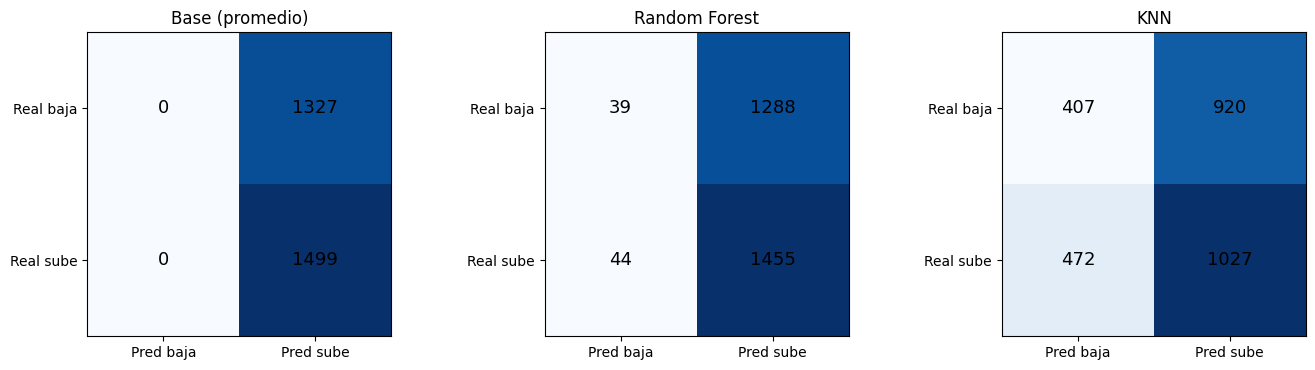

In [6]:
y = test["target"].values
base_mu = train.groupby("ticker")["target"].mean()
preds = {
    "Base (promedio)": test["ticker"].map(base_mu).values,
    "Random Forest":   rf_grid.best_estimator_.predict(test[FEATS]),
    "KNN":             knn_grid.best_estimator_.predict(test[FEATS]),
}

rows = []
for n, p in preds.items():
    mse = mean_squared_error(y, p)
    rows.append({"Modelo": n, "MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, p),
                 "Accuracy (sube/baja)": accuracy_score(y > 0, p > 0), "F1": f1_score(y > 0, p > 0)})
metricas = pd.DataFrame(rows).set_index("Modelo")
display(metricas)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (n, p) in zip(ax, preds.items()):
    cm = confusion_matrix(y > 0, p > 0, labels=[False, True])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
    a.set_xticks([0, 1]); a.set_xticklabels(["Pred baja", "Pred sube"])
    a.set_yticks([0, 1]); a.set_yticklabels(["Real baja", "Real sube"]); a.set_title(n)
plt.tight_layout(); plt.savefig("matrices_confusion.png", dpi=150); plt.show()

## 6. Test de Diebold-Mariano
**H0:** los dos modelos tienen la misma precision predictiva. **H1:** no la tienen.
Se toma la diferencia de perdidas d_t = e1_t² - e2_t² (error cuadratico por dia, promediado entre acciones). Estadistico DM = media(d) / error estandar, con la correccion de Harvey et al. para muestras finitas (distribucion t).
- **DM < 0** → el modelo 1 tiene menor error.  **DM > 0** → el modelo 2 es mejor.
- **p < 0.05** → la diferencia es estadisticamente significativa; si no, es ruido.

In [7]:
def perdida_diaria(p):
    e2 = (y - p) ** 2
    return pd.Series(e2, index=test["date"].values).groupby(level=0).mean()

def dm_test(l1, l2, h=1):
    d = (l1 - l2).values; n = len(d)
    stat = d.mean() / np.sqrt(np.var(d, ddof=0) / n)
    stat *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)        # correccion Harvey
    pval = 2 * (1 - stats.t.cdf(abs(stat), df=n - 1))
    return stat, pval

L = {k: perdida_diaria(v) for k, v in preds.items()}
pares = [("Random Forest", "Base (promedio)"), ("KNN", "Base (promedio)"), ("Random Forest", "KNN")]
res = []
for a, b in pares:
    s, p = dm_test(L[a], L[b])
    ganador = (a if s < 0 else b) if p < 0.05 else "Sin diferencia significativa"
    res.append({"Modelo 1": a, "Modelo 2": b, "Estadistico DM": s, "p-value": p, "Conclusion (5%)": ganador})
dm_tabla = pd.DataFrame(res); display(dm_tabla)

,Modelo 1,Modelo 2,Estadistico DM,p-value,Conclusion (5%)
0,Random Forest,Base (promedio),1.321985,0.186816,Sin diferencia significativa
1,KNN,Base (promedio),0.319347,0.749605,Sin diferencia significativa
2,Random Forest,KNN,0.872461,0.383402,Sin diferencia significativa


## 7. Optimizacion de carteras (Frontera Eficiente de Markowitz)
Cada 21 dias habiles (rebalanceo mensual):
- **Retorno esperado (μ):** promedio de las predicciones del modelo de los ultimos 21 dias, anualizado (×252).
- **Covarianza (Σ):** de los ultimos 252 dias de retornos reales, anualizada.
- **Optimizacion:** maximizar el ratio de Sharpe, solo posiciones largas, suma de pesos = 1 y maximo 40% por activo.

Se comparan: cartera igualitaria, Markowitz con μ historico, con μ de KNN y con μ de Random Forest.

,Retorno anual,Volatilidad,Sharpe,Sortino,Max Drawdown,Retorno acumulado
Igualitaria,0.215,0.187,0.936,1.408,-0.210,0.425
Markowitz + historico,0.170,0.202,0.640,0.931,-0.266,0.306
Markowitz + KNN,0.236,0.181,1.084,1.674,-0.146,0.482
Markowitz + Random Forest,0.179,0.180,0.774,1.151,-0.176,0.339


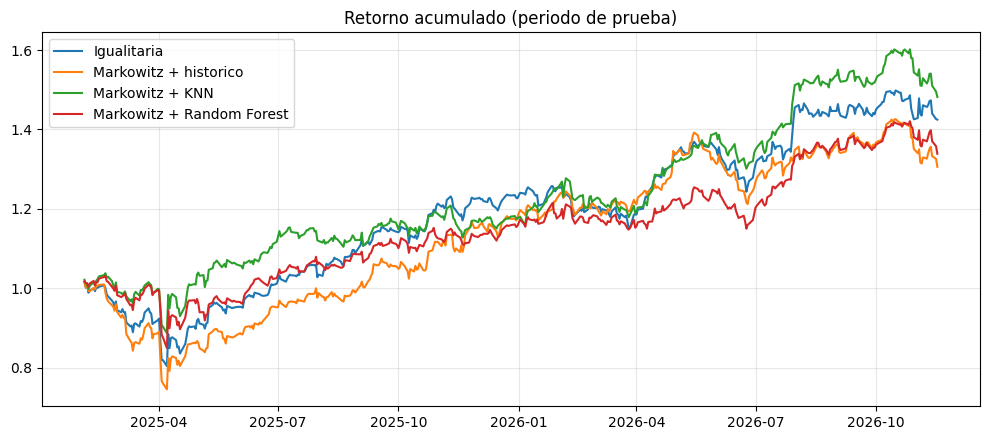

Pesos promedio Markowitz + RF:
AAPL     0.088
MSFT     0.237
AMZN     0.024
GOOGL    0.112
JPM      0.170
XOM      0.369
dtype: float64


In [8]:
act = test.pivot(index="date", columns="ticker", values="target")[TICKERS]

def pivot_pred(p):
    t = test[["date", "ticker"]].copy(); t["p"] = p
    return t.pivot(index="date", columns="ticker", values="p")[TICKERS]

pred_rf, pred_knn = pivot_pred(preds["Random Forest"]), pivot_pred(preds["KNN"])

def max_sharpe(mu, cov, rf=RF_ANUAL, wmax=0.40):
    n = len(mu)
    obj = lambda w: -(w @ mu - rf) / np.sqrt(w @ cov @ w)
    r = minimize(obj, np.ones(n) / n, bounds=[(0, wmax)] * n,
                 constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
    return r.x if r.success else np.ones(n) / n

def backtest(modo, pred_df=None, REB=21, LB=20):
    out, pesos = [], []
    fechas = act.index
    for i in range(LB, len(fechas), REB):
        d = fechas[i]
        hist = rets.loc[:d].tail(252)
        cov = hist.cov().values * 252
        if modo == "igual":
            w = np.ones(len(TICKERS)) / len(TICKERS)
        elif modo == "historico":
            w = max_sharpe(hist.mean().values * 252, cov)
        else:
            w = max_sharpe(pred_df.iloc[i - LB:i + 1].mean().values * 252, cov)
        pesos.append(pd.Series(w, index=TICKERS, name=d))
        out.append(act.iloc[i:i + REB] @ w)
    return pd.concat(out), pd.DataFrame(pesos)

r_eq, _         = backtest("igual")
r_hist, w_hist  = backtest("historico")
r_knn, w_knn    = backtest("modelo", pred_knn)
r_rf, w_rf      = backtest("modelo", pred_rf)

def perf(r):
    ann = r.mean() * 252; vol = r.std() * np.sqrt(252)
    down = np.sqrt((np.minimum(r - RF_ANUAL / 252, 0) ** 2).mean()) * np.sqrt(252)
    cum = (1 + r).cumprod()
    return {"Retorno anual": ann, "Volatilidad": vol, "Sharpe": (ann - RF_ANUAL) / vol,
            "Sortino": (ann - RF_ANUAL) / down, "Max Drawdown": (cum / cum.cummax() - 1).min(),
            "Retorno acumulado": cum.iloc[-1] - 1}

carteras = {"Igualitaria": r_eq, "Markowitz + historico": r_hist,
            "Markowitz + KNN": r_knn, "Markowitz + Random Forest": r_rf}
tabla_port = pd.DataFrame({k: perf(v) for k, v in carteras.items()}).T
display(tabla_port.style.format("{:.3f}"))

plt.figure(figsize=(10, 4.5))
for k, v in carteras.items(): plt.plot((1 + v).cumprod(), label=k)
plt.title("Retorno acumulado (periodo de prueba)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("carteras_acumulado.png", dpi=150); plt.show()
print("Pesos promedio Markowitz + RF:"); print(w_rf.mean().round(3))

## 8. Frontera Eficiente (ultima fecha, con μ del Random Forest)

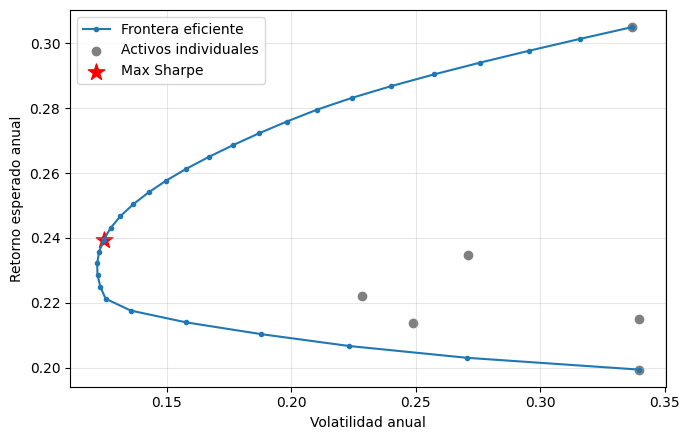

In [9]:
d = act.index[-1]
hist = rets.loc[:d].tail(252); cov = hist.cov().values * 252
mu = pred_rf.iloc[-21:].mean().values * 252

def frontera(mu, cov, n=30):
    pts = []
    for tr in np.linspace(mu.min(), mu.max(), n):
        r = minimize(lambda w: w @ cov @ w, np.ones(len(mu)) / len(mu), bounds=[(0, 1)] * len(mu),
                     constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                  {"type": "eq", "fun": lambda w, tr=tr: w @ mu - tr}], method="SLSQP")
        if r.success: pts.append((np.sqrt(r.x @ cov @ r.x), tr))
    return np.array(pts)

fr = frontera(mu, cov)
w_opt = max_sharpe(mu, cov, wmax=1.0)
plt.figure(figsize=(7, 4.5))
plt.plot(fr[:, 0], fr[:, 1], "-o", ms=3, label="Frontera eficiente")
plt.scatter(np.sqrt(np.diag(cov)), mu, c="gray", label="Activos individuales")
plt.scatter(np.sqrt(w_opt @ cov @ w_opt), w_opt @ mu, c="red", marker="*", s=150, label="Max Sharpe")
plt.xlabel("Volatilidad anual"); plt.ylabel("Retorno esperado anual"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("frontera_eficiente.png", dpi=150); plt.show()

## 9. Guardar resultados (para el informe PDF)

In [10]:
metricas.to_csv("metricas_modelos.csv"); dm_tabla.to_csv("diebold_mariano.csv")
tabla_port.to_csv("metricas_carteras.csv"); pd.concat([hp_rf, hp_knn]).to_csv("hiperparametros.csv", index=False)
print("Listo. Archivos .csv y .png guardados.")

Listo. Archivos .csv y .png guardados.
